## Índice

1. Introducción y objetivos
2. Carga y exploración inicial de datos
3. Limpieza y preparación de datos
4. Evolución nacional del Índice de Precios de Vivienda
5. Comparación entre vivienda nueva y segunda mano
6. Análisis regional: Andalucía, Madrid y Cataluña
7. Análisis de las variaciones interanuales
8. Revisión de calidad de los datos
9. Conclusiones finales

# Análisis exploratorio del mercado de la vivienda en España (2014–2026)

## 1. Introducción

### Objetivo del proyecto

El objetivo de este proyecto es analizar la evolución del Índice de Precios de Vivienda (IPV) en España entre 2014 y 2026, utilizando datos oficiales del Instituto Nacional de Estadística (INE).

El análisis pretende responder a las siguientes preguntas:

- ¿Cómo ha evolucionado el índice de precios de la vivienda en España?
- ¿Qué diferencias existen entre la vivienda nueva y la vivienda de segunda mano?
- ¿Qué comunidad ha experimentado un mayor crecimiento relativo entre Andalucía, Madrid y Cataluña?
- ¿En qué periodos se han producido las mayores aceleraciones y desaceleraciones del crecimiento interanual?

### Herramientas utilizadas

- **Python:** procesamiento y análisis de datos.
- **Pandas:** limpieza, transformación y manipulación de datos.
- **Matplotlib:** visualización de resultados.
- **Jupyter Notebook:** desarrollo y documentación del análisis.

### Fuente de datos

Instituto Nacional de Estadística (INE), Índice de Precios de Vivienda (IPV).

**Periodo analizado:** 2014T1–2026T2 para el análisis regional, con comparaciones nacionales según los periodos seleccionados.

**Nota metodológica:** el IPV mide la evolución relativa de los precios de la vivienda. No representa directamente precios de compraventa en euros.

# Análisis exploratorio del mercado de la vivienda en España

## Evolución de los precios de compra (2014–2026)

Este proyecto analiza la evolución de los precios de la vivienda en España utilizando datos oficiales del Instituto Nacional de Estadística (INE).

El objetivo es identificar tendencias y diferencias territoriales, y explorar su relación con factores demográficos y de oferta de vivienda.

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("../data/79563.csv", sep=";")
df.head()

,Total Nacional,Comunidades y Ciudades Autónomas,"General, vivienda nueva y de segunda mano",Índices y tasas,Periodo,Total
0,Nacional,NaN,General,Índice,2026T2,"111,095"
1,Nacional,NaN,General,Índice,2026T1,"107,458"
2,Nacional,NaN,General,Índice,2025T4,"103,805"
3,Nacional,NaN,General,Índice,2025T3,"101,937"
4,Nacional,NaN,General,Índice,2025T2,"99,043"


In [3]:
df.shape

(18720, 6)

In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 18720 entries, 0 to 18719
Data columns (total 6 columns):
 #   Column                                     Non-Null Count  Dtype
---  ------                                     --------------  -----
 0   Total Nacional                             18720 non-null  str  
 1   Comunidades y Ciudades Autónomas           17784 non-null  str  
 2   General, vivienda nueva y de segunda mano  18720 non-null  str  
 3   Índices y tasas                            18720 non-null  str  
 4   Periodo                                    18720 non-null  str  
 5   Total                                      17472 non-null  str  
dtypes: str(6)
memory usage: 877.6 KB


In [5]:
df.isna().sum()

Total Nacional                                  0
Comunidades y Ciudades Autónomas              936
General, vivienda nueva y de segunda mano       0
Índices y tasas                                 0
Periodo                                         0
Total                                        1248
dtype: int64

In [6]:
df[df["Total"].isna()].head(10)

,Total Nacional,Comunidades y Ciudades Autónomas,"General, vivienda nueva y de segunda mano",Índices y tasas,Periodo,Total
17160,Nacional,18 Ceuta,Vivienda nueva,Índice,2026T2,NaN
17161,Nacional,18 Ceuta,Vivienda nueva,Índice,2026T1,NaN
17162,Nacional,18 Ceuta,Vivienda nueva,Índice,2025T4,NaN
17163,Nacional,18 Ceuta,Vivienda nueva,Índice,2025T3,NaN
17164,Nacional,18 Ceuta,Vivienda nueva,Índice,2025T2,NaN
17165,Nacional,18 Ceuta,Vivienda nueva,Índice,2025T1,NaN
17166,Nacional,18 Ceuta,Vivienda nueva,Índice,2024T4,NaN
17167,Nacional,18 Ceuta,Vivienda nueva,Índice,2024T3,NaN
17168,Nacional,18 Ceuta,Vivienda nueva,Índice,2024T2,NaN
17169,Nacional,18 Ceuta,Vivienda nueva,Índice,2024T1,NaN


In [7]:
df[df["Total"].isna()]["Comunidades y Ciudades Autónomas"].value_counts()

Comunidades y Ciudades Autónomas
18 Ceuta      624
19 Melilla    624
Name: count, dtype: int64

In [8]:
df[df["Total"].isna()]["General, vivienda nueva y de segunda mano"].value_counts()

General, vivienda nueva y de segunda mano
Vivienda nueva           624
Vivienda segunda mano    624
Name: count, dtype: int64

In [9]:
df[df["Total"].isna()]["Índices y tasas"].value_counts()

Índices y tasas
Índice                           312
Variación trimestral             312
Variación anual                  312
Variación en lo que va de año    312
Name: count, dtype: int64

In [10]:
type(df["Total"].iloc[0])

str

In [11]:
df["Total_numerico"] = pd.to_numeric(
    df["Total"].str.replace(",", "."),
    errors="coerce"
)

In [12]:
df[["Total", "Total_numerico"]].head()

,Total,Total_numerico
0,"111,095",111.095
1,"107,458",107.458
2,"103,805",103.805
3,"101,937",101.937
4,"99,043",99.043


In [13]:
df["Total_numerico"].dtype

dtype('float64')

In [14]:
df_nacional = df[
    df["Comunidades y Ciudades Autónomas"].isna()
]

In [15]:
df_nacional.shape

(936, 7)

In [16]:
df_nacional["General, vivienda nueva y de segunda mano"].unique()

<StringArray>
['General', 'Vivienda nueva', 'Vivienda segunda mano']
Length: 3, dtype: str

In [17]:
df_general = df_nacional[
    df_nacional["General, vivienda nueva y de segunda mano"] == "General"
]

In [18]:
df_general.shape

(312, 7)

In [19]:
df_general["Índices y tasas"].unique()

<StringArray>
[                       'Índice',          'Variación trimestral',
               'Variación anual', 'Variación en lo que va de año']
Length: 4, dtype: str

In [20]:
df_indice = df_general[
    df_general["Índices y tasas"] == "Índice"
]

In [21]:
df_indice["Periodo"].str[:4].head()

0    2026
1    2026
2    2025
3    2025
4    2025
Name: Periodo, dtype: str

In [22]:
df_indice = df_indice.copy()

df_indice["Año"] = df_indice["Periodo"].str[:4].astype(int)

In [23]:
df_indice[["Periodo", "Año"]].head()

,Periodo,Año
0,2026T2,2026
1,2026T1,2026
2,2025T4,2025
3,2025T3,2025
4,2025T2,2025


In [24]:
df_indice["Año"] = df_indice["Periodo"].str[:4].astype(int)

In [25]:
df_indice.shape

(78, 8)

In [26]:
df_indice["Año"].between(2014, 2026)

0      True
1      True
2      True
3      True
4      True
      ...  
73    False
74    False
75    False
76    False
77    False
Name: Año, Length: 78, dtype: bool

In [27]:
df_periodo = df_indice[
    df_indice["Año"].between(2014, 2026)
]

df_periodo.shape



(50, 8)

In [28]:
df_periodo[["Periodo", "Total_numerico"]].head(10)

,Periodo,Total_numerico
0,2026T2,111.095
1,2026T1,107.458
2,2025T4,103.805
3,2025T3,101.937
4,2025T2,99.043
5,2025T1,95.215
6,2024T4,91.956
7,2024T3,90.337
8,2024T2,87.870
9,2024T1,84.833


In [29]:
df_periodo[df_periodo["Periodo"] == "2014T2"]

,Total Nacional,Comunidades y Ciudades Autónomas,"General, vivienda nueva y de segunda mano",Índices y tasas,Periodo,Total,Total_numerico,Año
48,Nacional,NaN,General,Índice,2014T2,"53,809",53.809,2014


In [30]:
df_periodo[df_periodo["Periodo"] == "2026T2"]

,Total Nacional,Comunidades y Ciudades Autónomas,"General, vivienda nueva y de segunda mano",Índices y tasas,Periodo,Total,Total_numerico,Año
0,Nacional,NaN,General,Índice,2026T2,"111,095",111.095,2026


In [31]:
indice_2014 = 53.809
indice_2026 = 111.095

variacion = ((indice_2026 - indice_2014) / indice_2014) * 100

print(variacion)

106.46174431786505


In [32]:
round(variacion, 2)

106.46

In [33]:
indice_2014 = df_periodo.loc[
    df_periodo["Periodo"] == "2014T2",
    "Total_numerico"
].iloc[0]

print(indice_2014)

53.809


In [34]:
indice_2014 = df_periodo.loc[
    df_periodo["Periodo"] == "2014T2",
    "Total_numerico"
].iloc[0]

In [35]:
indice_2026 = df_periodo.loc[
    df_periodo["Periodo"] == "2026T2",
    "Total_numerico"
].iloc[0]

print(indice_2026)

111.095


In [36]:
variacion_automatizada = (
    (indice_2026 - indice_2014) / indice_2014
) * 100

print(round(variacion_automatizada, 2))

106.46


In [37]:
import matplotlib.pyplot as plt

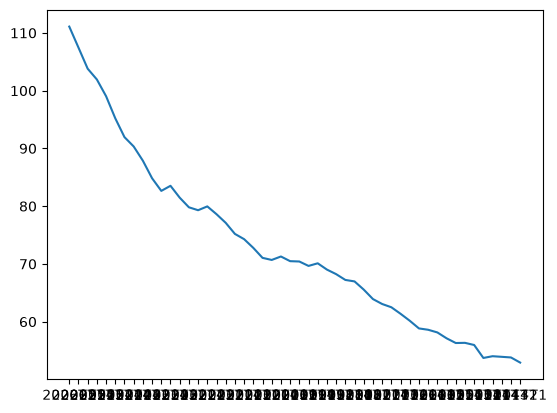

In [38]:
plt.plot(
    df_periodo["Periodo"],
    df_periodo["Total_numerico"]
)

plt.show()

In [39]:
df_ordenado = df_periodo.sort_values("Periodo")

In [40]:
df_ordenado[["Periodo", "Total_numerico"]].head()

,Periodo,Total_numerico
49,2014T1,52.921
48,2014T2,53.809
47,2014T3,53.919
46,2014T4,54.025
45,2015T1,53.723


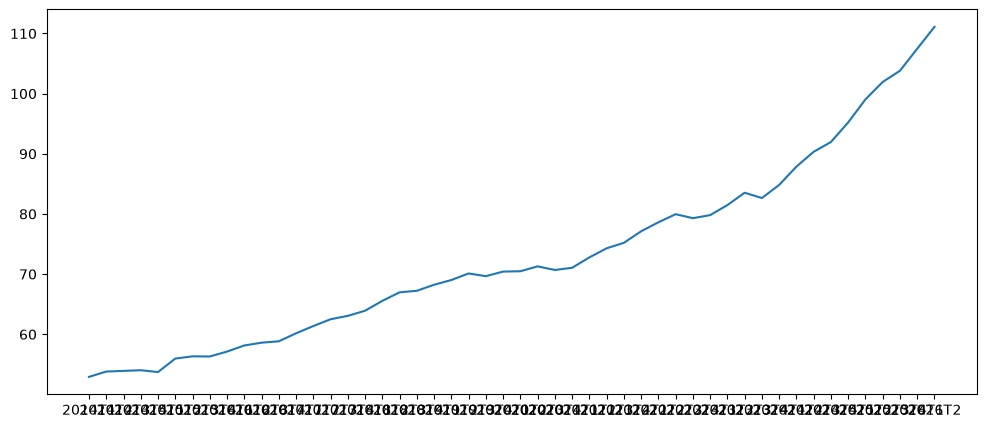

In [41]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_ordenado["Periodo"],
    df_ordenado["Total_numerico"]
)

plt.show()

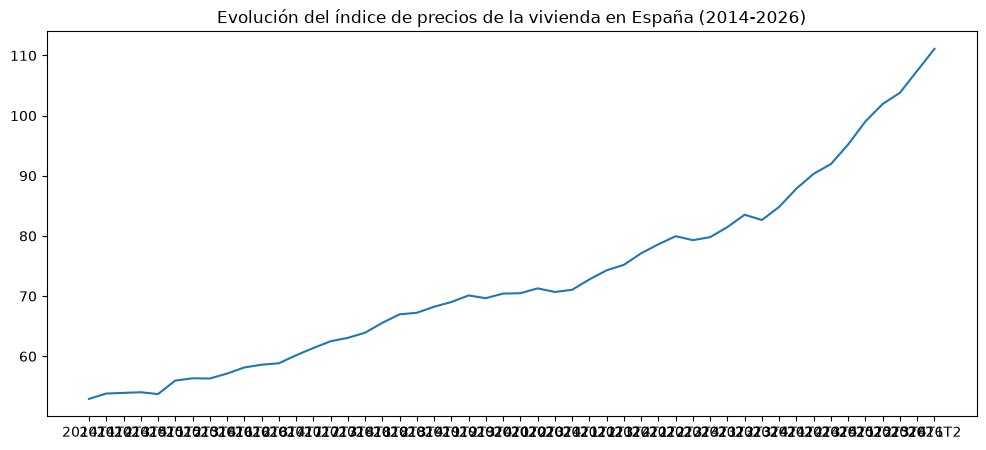

In [42]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_ordenado["Periodo"],
    df_ordenado["Total_numerico"]
)

plt.title("Evolución del índice de precios de la vivienda en España (2014-2026)")

plt.show()

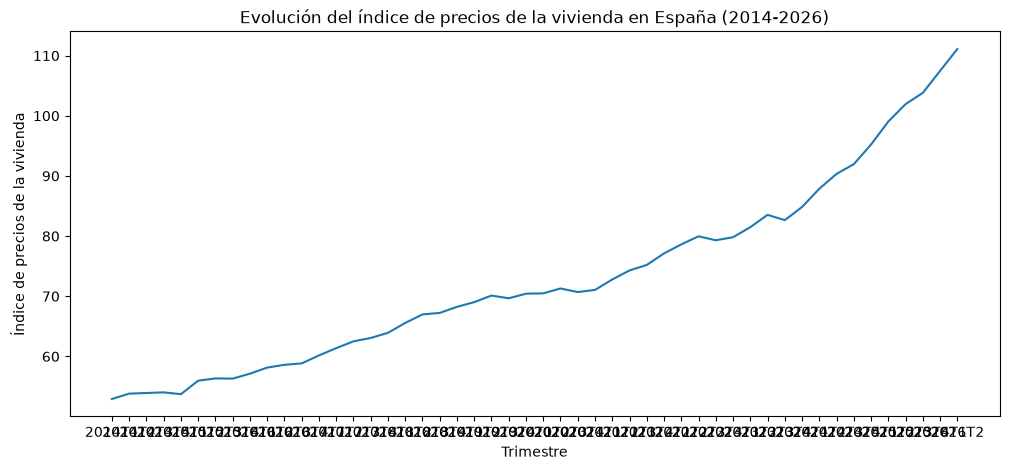

In [43]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_ordenado["Periodo"],
    df_ordenado["Total_numerico"]
)

plt.title("Evolución del índice de precios de la vivienda en España (2014-2026)")

plt.xlabel("Trimestre")
plt.ylabel("Índice de precios de la vivienda")

plt.show()

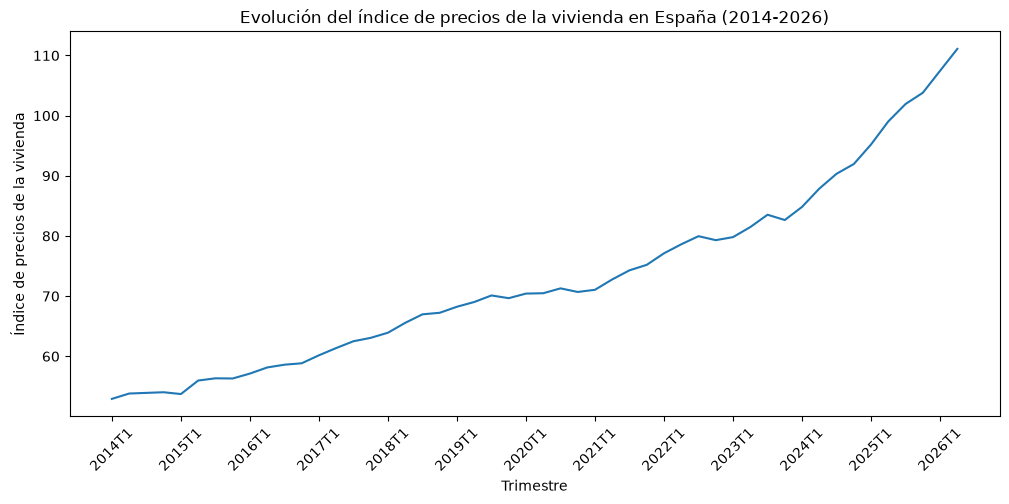

In [44]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_ordenado["Periodo"],
    df_ordenado["Total_numerico"]
)

plt.title("Evolución del índice de precios de la vivienda en España (2014-2026)")
plt.xlabel("Trimestre")
plt.ylabel("Índice de precios de la vivienda")

plt.xticks(
    df_ordenado["Periodo"][::4],
    rotation=45
)

plt.show()

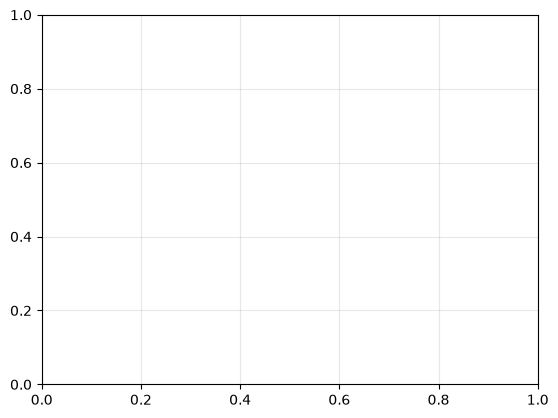

In [45]:
plt.grid(True, alpha=0.3)

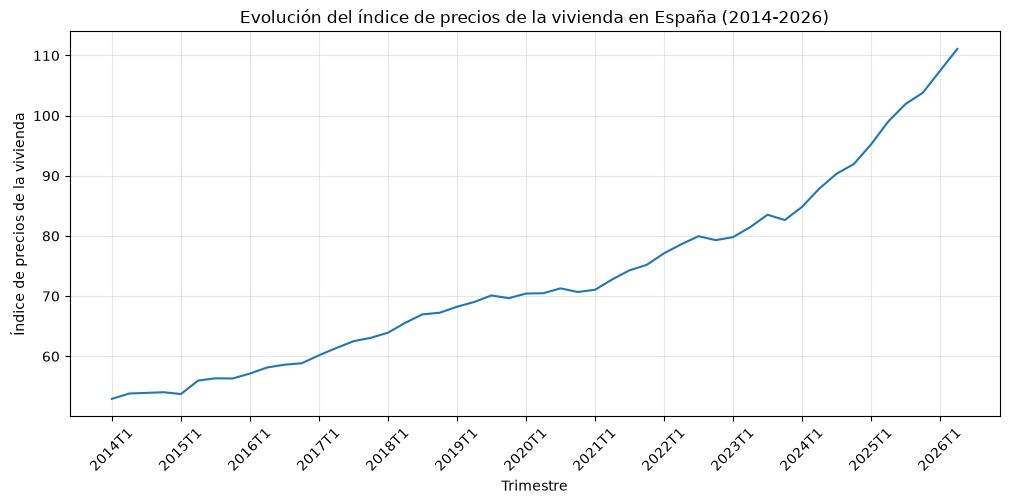

In [46]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_ordenado["Periodo"],
    df_ordenado["Total_numerico"]
)

plt.title("Evolución del índice de precios de la vivienda en España (2014-2026)")
plt.xlabel("Trimestre")
plt.ylabel("Índice de precios de la vivienda")

plt.xticks(
    df_ordenado["Periodo"][::4],
    rotation=45
)

plt.grid(True, alpha=0.3)

plt.show()

### Análisis de la evolución del índice de precios de la vivienda en España (2014–2026)

El Índice de Precios de Vivienda (IPV) del Instituto Nacional de Estadística (INE) muestra una tendencia general ascendente durante el periodo analizado.

Entre el segundo trimestre de 2014 y el segundo trimestre de 2026, el índice general aumentó aproximadamente un **106,46 %**, lo que significa que su valor se ha situado en algo más del doble del registrado al inicio de la comparación.

La evolución no ha sido uniforme durante todo el periodo, observándose una aceleración del crecimiento en los últimos años.

Es importante señalar que el IPV mide la evolución relativa de los precios de compraventa de viviendas, pero no permite conocer directamente su precio medio en euros.


In [47]:
df_nacional["General, vivienda nueva y de segunda mano"].value_counts()

General, vivienda nueva y de segunda mano
General                  312
Vivienda nueva           312
Vivienda segunda mano    312
Name: count, dtype: int64

In [48]:
df_tipos = df_nacional[
    df_nacional["General, vivienda nueva y de segunda mano"].isin(
        ["Vivienda nueva", "Vivienda segunda mano"]
    )
]

In [49]:
df_tipos.shape

(624, 7)

In [50]:
df_tipos_indice = df_tipos[
    df_tipos["Índices y tasas"] == "Índice"
]

In [51]:
df_tipos_indice.shape

(156, 7)

In [52]:
df_tipos_indice = df_tipos_indice.copy()

df_tipos_indice["Año"] = df_tipos_indice["Periodo"].str[:4].astype(int)

In [53]:
"2018T3"[:4]

'2018'

In [54]:
df_tipos_periodo = df_tipos_indice[
    df_tipos_indice["Año"].between(2014, 2026)
]

In [55]:
df_tipos_periodo.shape

(100, 8)

In [56]:
df_tipos_periodo[
    ["Periodo", "General, vivienda nueva y de segunda mano", "Total_numerico"]
].head(10)

,Periodo,"General, vivienda nueva y de segunda mano",Total_numerico
312,2026T2,Vivienda nueva,107.228
313,2026T1,Vivienda nueva,106.129
314,2025T4,Vivienda nueva,102.559
315,2025T3,Vivienda nueva,100.371
316,2025T2,Vivienda nueva,99.810
317,2025T1,Vivienda nueva,97.260
318,2024T4,Vivienda nueva,92.211
319,2024T3,Vivienda nueva,91.500
320,2024T2,Vivienda nueva,89.036
321,2024T1,Vivienda nueva,86.656


In [57]:
df_tipos_ordenado = df_tipos_periodo.sort_values("Periodo")

In [58]:
df_tipos_ordenado[
    ["Periodo", "General, vivienda nueva y de segunda mano", "Total_numerico"]
].head(6)

,Periodo,"General, vivienda nueva y de segunda mano",Total_numerico
361,2014T1,Vivienda nueva,45.772
673,2014T1,Vivienda segunda mano,54.216
672,2014T2,Vivienda segunda mano,55.238
360,2014T2,Vivienda nueva,46.057
359,2014T3,Vivienda nueva,46.603
671,2014T3,Vivienda segunda mano,55.245


In [59]:
df_nueva = df_tipos_ordenado[
    df_tipos_ordenado["General, vivienda nueva y de segunda mano"] == "Vivienda nueva"
]

In [60]:
df_nueva.shape

(50, 8)

In [61]:
df_segunda_mano = df_tipos_ordenado[
    df_tipos_ordenado["General, vivienda nueva y de segunda mano"] == "Vivienda segunda mano"
]

In [62]:
df_segunda_mano.shape

(50, 8)

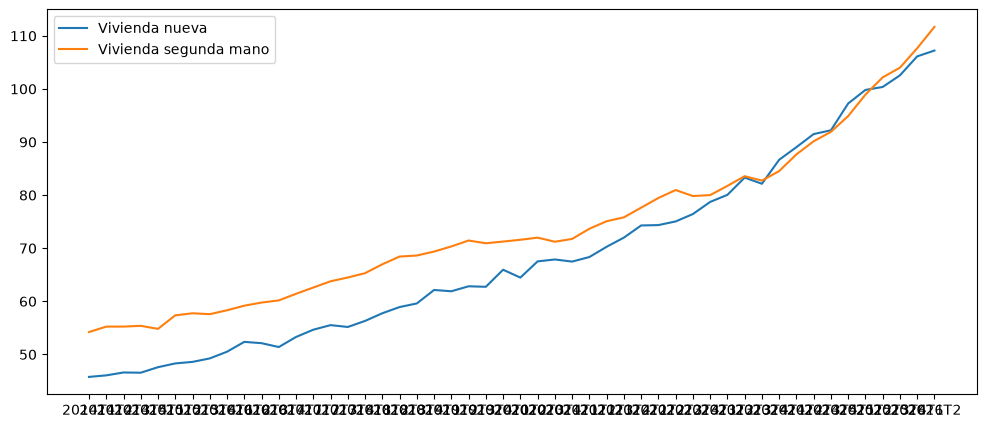

In [63]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_nueva["Periodo"],
    df_nueva["Total_numerico"],
    label="Vivienda nueva"
)

plt.plot(
    df_segunda_mano["Periodo"],
    df_segunda_mano["Total_numerico"],
    label="Vivienda segunda mano"
)

plt.legend()
plt.show()

Text(0.5, 1.0, 'Evolución del precio de la vivienda nueva y de segunda mano en España (2014-2026)')

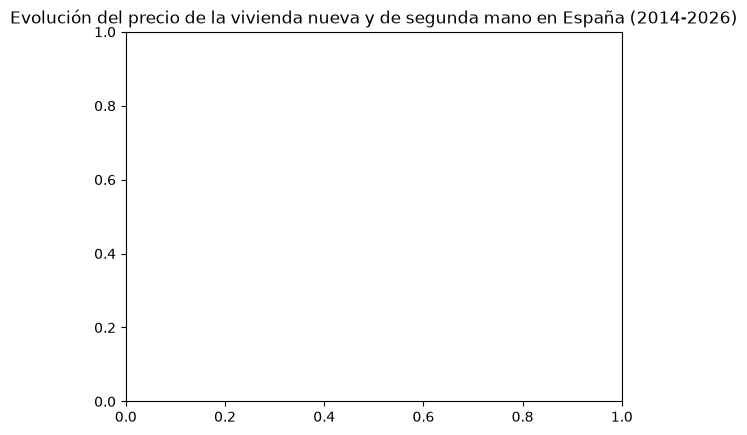

In [64]:
plt.title("Evolución del precio de la vivienda nueva y de segunda mano en España (2014-2026)")

Text(0, 0.5, 'Índice de precios de la vivienda')

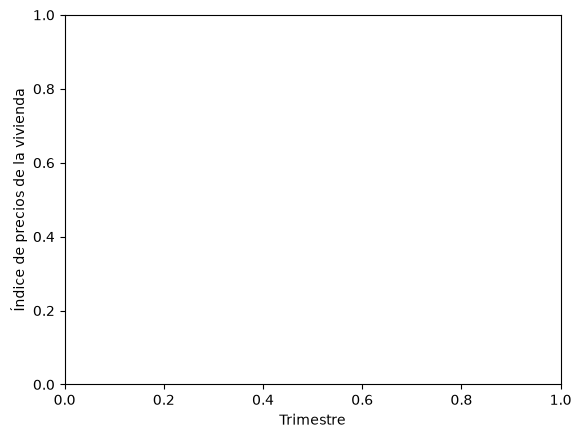

In [65]:
plt.xlabel("Trimestre")
plt.ylabel("Índice de precios de la vivienda")

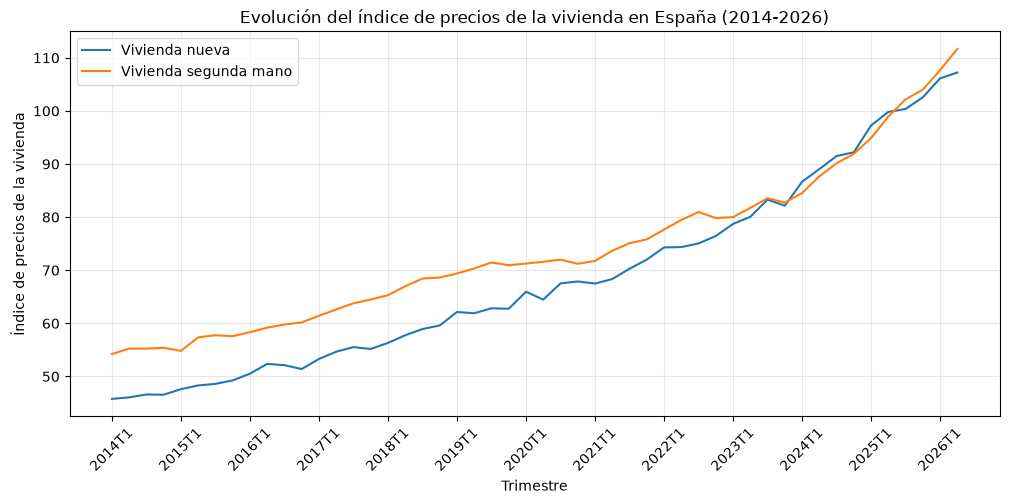

In [66]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_nueva["Periodo"],
    df_nueva["Total_numerico"],
    label="Vivienda nueva"
)

plt.plot(
    df_segunda_mano["Periodo"],
    df_segunda_mano["Total_numerico"],
    label="Vivienda segunda mano"
)

plt.title("Evolución del índice de precios de la vivienda en España (2014-2026)")
plt.xlabel("Trimestre")
plt.ylabel("Índice de precios de la vivienda")

plt.legend()
plt.xticks(df_nueva["Periodo"][::4], rotation=45)
plt.grid(True, alpha=0.3)
plt.show()

In [67]:
df_nueva[df_nueva["Periodo"] == "2014T2"]

,Total Nacional,Comunidades y Ciudades Autónomas,"General, vivienda nueva y de segunda mano",Índices y tasas,Periodo,Total,Total_numerico,Año
360,Nacional,NaN,Vivienda nueva,Índice,2014T2,"46,057",46.057,2014


In [68]:
df_nueva[df_nueva["Periodo"] == "2026T2"]

,Total Nacional,Comunidades y Ciudades Autónomas,"General, vivienda nueva y de segunda mano",Índices y tasas,Periodo,Total,Total_numerico,Año
312,Nacional,NaN,Vivienda nueva,Índice,2026T2,"107,228",107.228,2026


In [69]:
indice_nueva_2014 = df_nueva.loc[
    df_nueva["Periodo"] == "2014T2",
    "Total_numerico"
].iloc[0]

print(indice_nueva_2014)

46.057


In [70]:
indice_nueva_2026 = df_nueva.loc[
    df_nueva["Periodo"] == "2026T2",
    "Total_numerico"
].iloc[0]

print(indice_nueva_2026)

107.228


In [71]:
crecimiento_nueva = (
    (indice_nueva_2026 - indice_nueva_2014)
    / indice_nueva_2014
) * 100

print(round(crecimiento_nueva, 2))

132.82


In [72]:
indice_segunda_mano_2014 = df_segunda_mano.loc[
    df_segunda_mano["Periodo"] == "2014T2",
    "Total_numerico"
].iloc[0]

print(indice_segunda_mano_2014)

55.238


In [73]:
indice_segunda_mano_2026 = df_segunda_mano.loc[
    df_segunda_mano["Periodo"] == "2026T2",
    "Total_numerico"
].iloc[0]

print(indice_segunda_mano_2026)

111.682


In [74]:
crecimiento_segunda_mano = (
    (indice_segunda_mano_2026 - indice_segunda_mano_2014)
    / indice_segunda_mano_2014
) * 100

print(round(crecimiento_segunda_mano, 2))

102.18


### Análisis comparativo: vivienda nueva y vivienda de segunda mano (2014–2026)

El análisis del Índice de Precios de Vivienda (IPV) del Instituto Nacional de Estadística (INE) muestra una tendencia ascendente tanto en la vivienda nueva como en la de segunda mano durante el periodo comprendido entre el segundo trimestre de 2014 y el segundo trimestre de 2026.

Sin embargo, el crecimiento no ha sido igual en ambas categorías:

- **Vivienda nueva:** incremento acumulado del **132,82 %**.
- **Vivienda de segunda mano:** incremento acumulado del **102,18 %**.

Por tanto, la vivienda nueva ha experimentado un crecimiento superior en **30,64 puntos porcentuales** respecto a la vivienda de segunda mano.

Estos resultados indican que los precios de compraventa de la vivienda nueva han aumentado proporcionalmente más durante el periodo analizado.

Es importante señalar que el IPV mide la evolución relativa de los precios, por lo que estos resultados no permiten determinar qué tipo de vivienda tiene un precio de venta más elevado en euros.


In [75]:
df["Comunidades y Ciudades Autónomas"].unique()

<StringArray>
[                             nan,                   '01 Andalucía',
                      '02 Aragón',     '03 Asturias, Principado de',
              '04 Balears, Illes',                    '05 Canarias',
                   '06 Cantabria',             '07 Castilla y León',
        '08 Castilla - La Mancha',                    '09 Cataluña',
        '10 Comunitat Valenciana',                 '11 Extremadura',
                     '12 Galicia',        '13 Madrid, Comunidad de',
           '14 Murcia, Región de', '15 Navarra, Comunidad Foral de',
                  '16 País Vasco',                   '17 Rioja, La',
                       '18 Ceuta',                     '19 Melilla']
Length: 20, dtype: str

In [76]:
df_comunidades = df[
    df["Comunidades y Ciudades Autónomas"].isin(
        ["01 Andalucía", "13 Madrid, Comunidad de", "09 Cataluña"]
    )
]

In [77]:
df_comunidades = df[
    df["Comunidades y Ciudades Autónomas"].isin(
        ["01 Andalucía", "13 Madrid, Comunidad de", "09 Cataluña"]
    )
]

In [78]:
df_comunidades["Comunidades y Ciudades Autónomas"].unique()

<StringArray>
['01 Andalucía', '09 Cataluña', '13 Madrid, Comunidad de']
Length: 3, dtype: str

In [79]:
df_comunidades.shape

(2808, 7)

In [80]:
df_comunidades_general = df_comunidades[
    df_comunidades["General, vivienda nueva y de segunda mano"] == "General"
]

In [81]:
df_comunidades_general.shape

(936, 7)

In [82]:
df_comunidades_indice = df_comunidades_general[
    df_comunidades_general["Índices y tasas"] == "Índice"
]

In [83]:
df_comunidades_indice.shape

(234, 7)

In [84]:
df_comunidades_indice = df_comunidades_indice.copy()

df_comunidades_indice["Año"] = (
    df_comunidades_indice["Periodo"].str[:4].astype(int)
)

In [85]:
df_comunidades_periodo = df_comunidades_indice[
    df_comunidades_indice["Año"].between(2014, 2026)
]

In [86]:
df_comunidades_periodo.shape

(150, 8)

In [87]:
df_comunidades_periodo.shape

(150, 8)

In [88]:
df_comunidades_ordenado = df_comunidades_periodo.sort_values("Periodo")

In [89]:
df_comunidades_ordenado["Periodo"].head(6)

12217    2014T1
985      2014T1
8473     2014T1
984      2014T2
8472     2014T2
12216    2014T2
Name: Periodo, dtype: str

In [90]:
df_andalucia = df_comunidades_ordenado[
    df_comunidades_ordenado["Comunidades y Ciudades Autónomas"] == "01 Andalucía"
]

In [91]:
df_andalucia.shape

(50, 8)

In [92]:
df_madrid = df_comunidades_ordenado[
    df_comunidades_ordenado["Comunidades y Ciudades Autónomas"] == "13 Madrid, Comunidad de"
]

In [93]:
df_madrid.shape

(50, 8)

In [94]:
df_madrid.shape

(50, 8)

In [95]:
df_cataluna = df_comunidades_ordenado[
    df_comunidades_ordenado["Comunidades y Ciudades Autónomas"] == "09 Cataluña"
]

In [96]:
df_cataluna.shape

(50, 8)

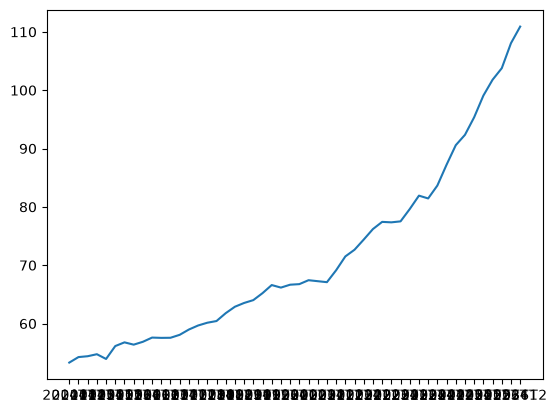

In [97]:
import matplotlib.pyplot as plt

plt.plot(df_andalucia["Periodo"], df_andalucia["Total_numerico"])

plt.show()

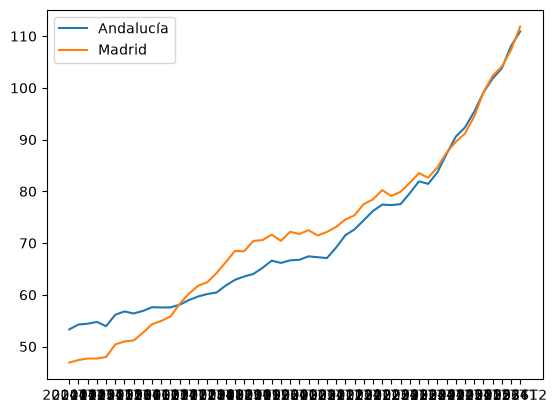

In [98]:
plt.plot(
    df_andalucia["Periodo"],
    df_andalucia["Total_numerico"],
    label="Andalucía"
)

plt.plot(
    df_madrid["Periodo"],
    df_madrid["Total_numerico"],
    label="Madrid"
)

plt.legend()
plt.show()

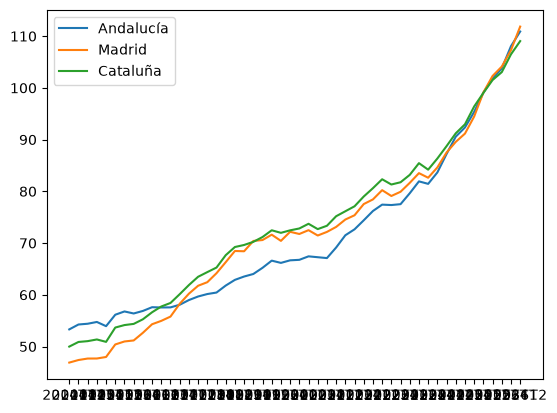

In [99]:
plt.plot(
    df_andalucia["Periodo"],
    df_andalucia["Total_numerico"],
    label="Andalucía"
)

plt.plot(
    df_madrid["Periodo"],
    df_madrid["Total_numerico"],
    label="Madrid"
)

plt.plot(
    df_cataluna["Periodo"],
    df_cataluna["Total_numerico"],
    label="Cataluña"
)

plt.legend()
plt.show()

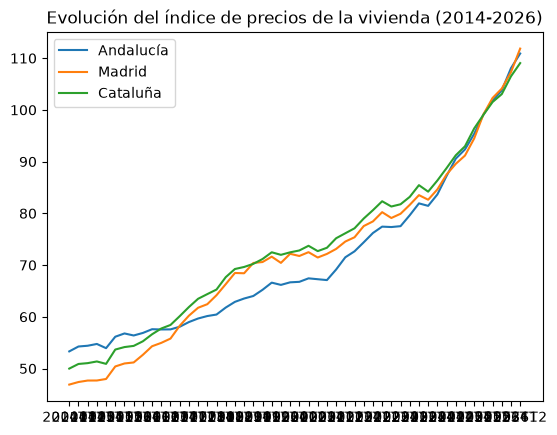

In [100]:
plt.plot(
    df_andalucia["Periodo"],
    df_andalucia["Total_numerico"],
    label="Andalucía"
)

plt.plot(
    df_madrid["Periodo"],
    df_madrid["Total_numerico"],
    label="Madrid"
)

plt.plot(
    df_cataluna["Periodo"],
    df_cataluna["Total_numerico"],
    label="Cataluña"
)

plt.title("Evolución del índice de precios de la vivienda (2014-2026)")

plt.legend()
plt.show()

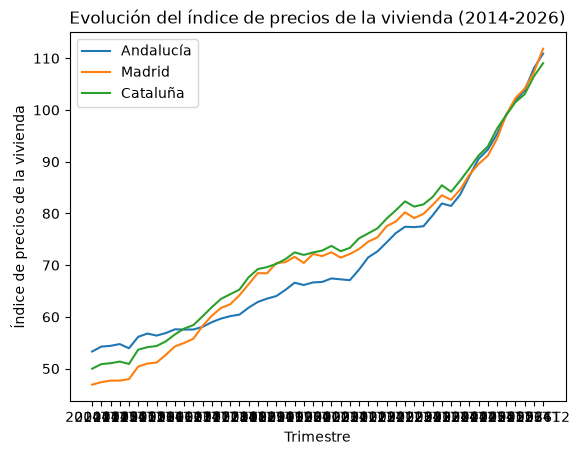

In [101]:
plt.plot(
    df_andalucia["Periodo"],
    df_andalucia["Total_numerico"],
    label="Andalucía"
)

plt.plot(
    df_madrid["Periodo"],
    df_madrid["Total_numerico"],
    label="Madrid"
)

plt.plot(
    df_cataluna["Periodo"],
    df_cataluna["Total_numerico"],
    label="Cataluña"
)

plt.title("Evolución del índice de precios de la vivienda (2014-2026)")

plt.xlabel("Trimestre")
plt.ylabel("Índice de precios de la vivienda")

plt.legend()
plt.show()

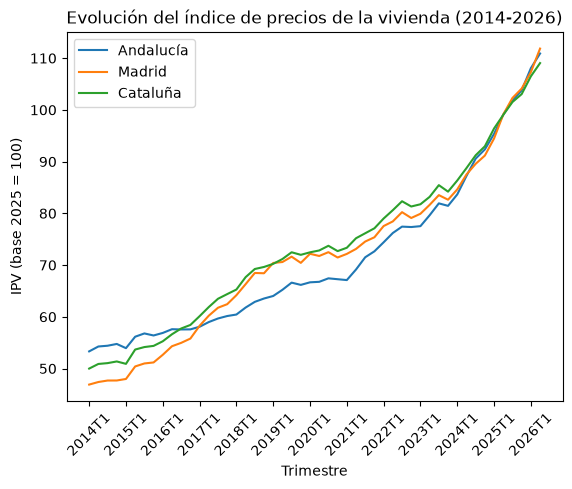

In [102]:
plt.plot(
    df_andalucia["Periodo"],
    df_andalucia["Total_numerico"],
    label="Andalucía"
)

plt.plot(
    df_madrid["Periodo"],
    df_madrid["Total_numerico"],
    label="Madrid"
)

plt.plot(
    df_cataluna["Periodo"],
    df_cataluna["Total_numerico"],
    label="Cataluña"
)

plt.title("Evolución del índice de precios de la vivienda (2014-2026)")
plt.xlabel("Trimestre")
plt.ylabel("IPV (base 2025 = 100)")

plt.xticks(df_andalucia["Periodo"][::4], rotation=45)

plt.legend()
plt.show()

In [103]:
df_andalucia[
    df_andalucia["Periodo"] == "2014T1"
][["Periodo", "Total_numerico"]]

,Periodo,Total_numerico
985,2014T1,53.316


In [104]:
indice_andalucia_2014 = df_andalucia.loc[
    df_andalucia["Periodo"] == "2014T1",
    "Total_numerico"
].iloc[0]

print(indice_andalucia_2014)

53.316


In [105]:
df_andalucia = df_andalucia.copy()

df_andalucia["Crecimiento_%"] = (
    (df_andalucia["Total_numerico"] / indice_andalucia_2014) - 1
) * 100

In [106]:
df_andalucia[["Periodo", "Crecimiento_%"]].head()

,Periodo,Crecimiento_%
985,2014T1,0.000000
984,2014T2,1.770575
983,2014T3,2.046290
982,2014T4,2.691500
981,2015T1,1.166629


In [107]:
indice_madrid_2014 = df_madrid.loc[
    df_madrid["Periodo"] == "2014T1",
    "Total_numerico"
].iloc[0]

print(indice_madrid_2014)

46.897


In [108]:
df_madrid = df_madrid.copy()

df_madrid["Crecimiento_%"] = (
    (df_madrid["Total_numerico"] / indice_madrid_2014) - 1
) * 100

In [109]:
df_madrid[["Periodo", "Crecimiento_%"]].head()

,Periodo,Crecimiento_%
12217,2014T1,0.000000
12216,2014T2,1.059769
12215,2014T3,1.667484
12214,2014T4,1.684543
12213,2015T1,2.311448


In [110]:
indice_cataluna_2014 = df_cataluna.loc[
    df_cataluna["Periodo"] == "2014T1",
    "Total_numerico"
].iloc[0]

print(indice_cataluna_2014)

49.99


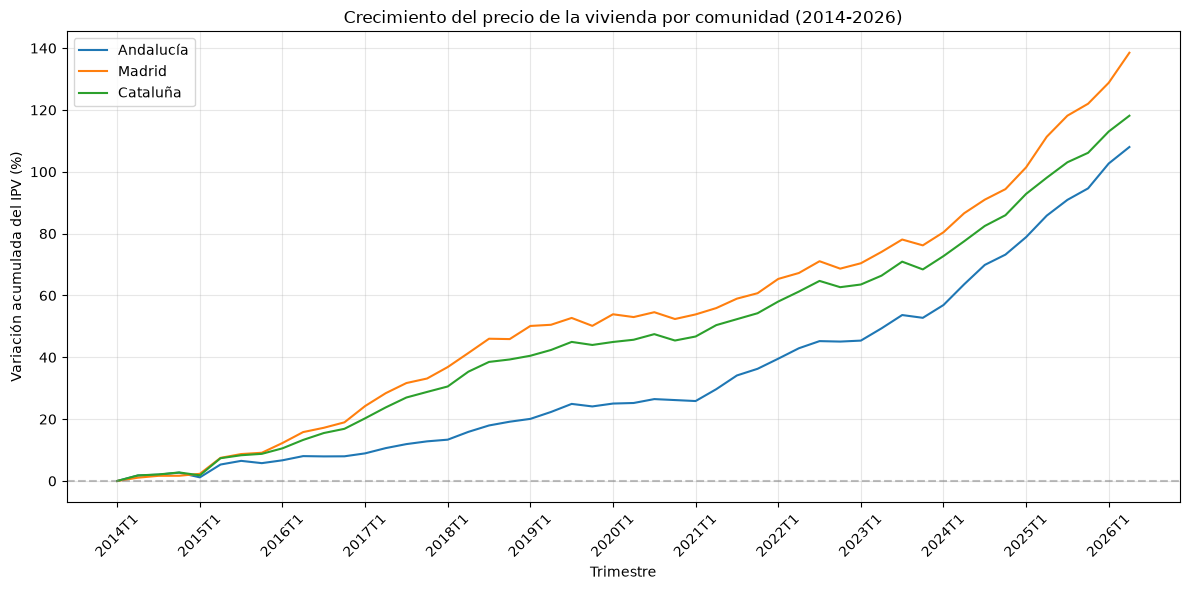

In [111]:
# 1. Calcular el crecimiento de Cataluña
indice_cataluna_2014 = df_cataluna.loc[
    df_cataluna["Periodo"] == "2014T1",
    "Total_numerico"
].iloc[0]

df_cataluna = df_cataluna.copy()

df_cataluna["Crecimiento_%"] = (
    (df_cataluna["Total_numerico"] / indice_cataluna_2014) - 1
) * 100


# 2. Crear la gráfica comparativa
plt.figure(figsize=(12, 6))

plt.plot(
    df_andalucia["Periodo"],
    df_andalucia["Crecimiento_%"],
    label="Andalucía"
)

plt.plot(
    df_madrid["Periodo"],
    df_madrid["Crecimiento_%"],
    label="Madrid"
)

plt.plot(
    df_cataluna["Periodo"],
    df_cataluna["Crecimiento_%"],
    label="Cataluña"
)


# 3. Mejorar la presentación
plt.title("Crecimiento del precio de la vivienda por comunidad (2014-2026)")
plt.xlabel("Trimestre")
plt.ylabel("Variación acumulada del IPV (%)")

plt.xticks(df_andalucia["Periodo"][::4], rotation=45)

plt.axhline(0, color="gray", linestyle="--", alpha=0.5)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [112]:
comparacion = pd.DataFrame({
    "Comunidad": ["Andalucía", "Madrid", "Cataluña"],
    "Crecimiento (%)": [
        df_andalucia["Crecimiento_%"].iloc[-1],
        df_madrid["Crecimiento_%"].iloc[-1],
        df_cataluna["Crecimiento_%"].iloc[-1]
    ]
})

comparacion = comparacion.sort_values(
    "Crecimiento (%)", ascending=False
)

comparacion.round(2)

,Comunidad,Crecimiento (%)
1,Madrid,138.50
2,Cataluña,118.14
0,Andalucía,108.01


### Análisis regional del mercado de la vivienda (2014-2026)

Se ha analizado la evolución del Índice de Precios de Vivienda (IPV) en Andalucía, Madrid y Cataluña entre el primer trimestre de 2014 y el segundo trimestre de 2026, tomando 2014T1 como periodo de referencia.

**Principales resultados:**

- **Madrid:** crecimiento acumulado del 138,50 %.
- **Cataluña:** crecimiento acumulado del 118,14 %.
- **Andalucía:** crecimiento acumulado del 108,01 %.

Madrid presenta el mayor crecimiento relativo del índice, superando a Andalucía en 30,49 puntos porcentuales.

Las tres comunidades han experimentado un aumento acumulado superior al 100 %, lo que refleja una tendencia alcista del índice durante el periodo estudiado.

**Conclusión:** Madrid lidera el crecimiento relativo del IPV entre las tres comunidades analizadas. Estos resultados permiten comparar la evolución de los índices, pero no los precios absolutos de las viviendas en euros.

**Fuente:** Instituto Nacional de Estadística (INE). Cálculos propios a partir del IPV.

In [113]:
df_andalucia["Variacion_interanual_%"] = (
    df_andalucia["Total_numerico"].pct_change(periods=4) * 100
)

df_madrid["Variacion_interanual_%"] = (
    df_madrid["Total_numerico"].pct_change(periods=4) * 100
)

df_cataluna["Variacion_interanual_%"] = (
    df_cataluna["Total_numerico"].pct_change(periods=4) * 100
)

In [114]:
df_madrid[
    ["Periodo", "Total_numerico", "Variacion_interanual_%"]
].head(8).round(2)

,Periodo,Total_numerico,Variacion_interanual_%
12217,2014T1,46.90,NaN
12216,2014T2,47.39,NaN
12215,2014T3,47.68,NaN
12214,2014T4,47.69,NaN
12213,2015T1,47.98,2.31
12212,2015T2,50.40,6.35
12211,2015T3,50.98,6.92
12210,2015T4,51.18,7.32


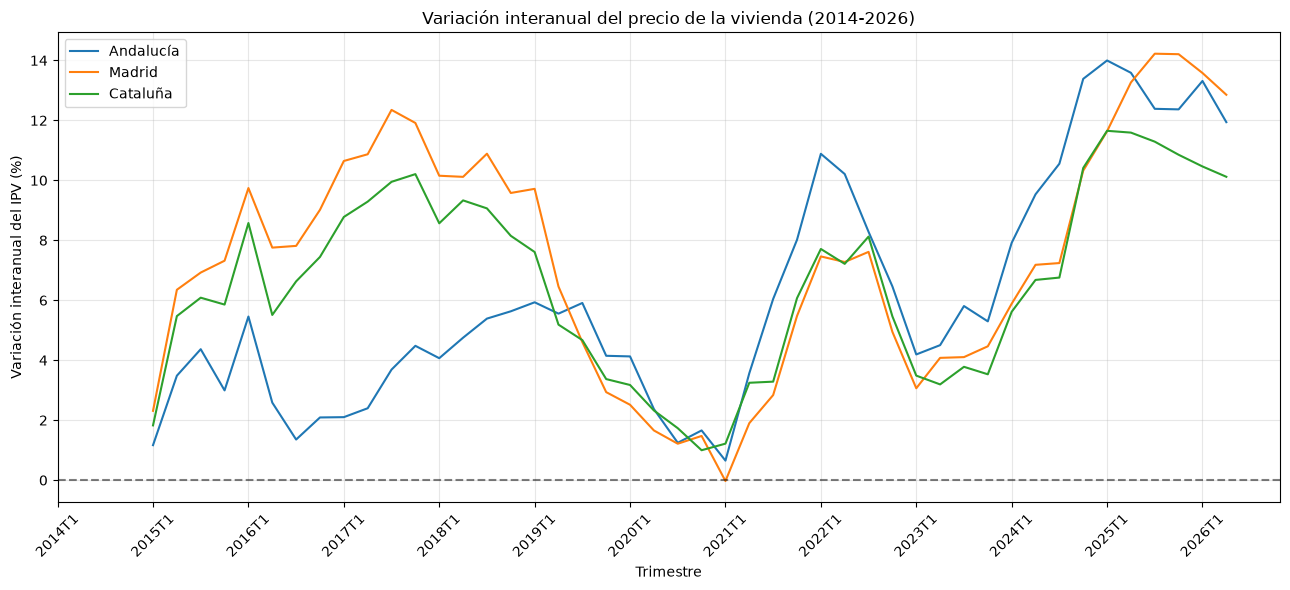

In [115]:
plt.figure(figsize=(13, 6))

plt.plot(
    df_andalucia["Periodo"],
    df_andalucia["Variacion_interanual_%"],
    label="Andalucía"
)

plt.plot(
    df_madrid["Periodo"],
    df_madrid["Variacion_interanual_%"],
    label="Madrid"
)

plt.plot(
    df_cataluna["Periodo"],
    df_cataluna["Variacion_interanual_%"],
    label="Cataluña"
)

plt.title("Variación interanual del precio de la vivienda (2014-2026)")
plt.xlabel("Trimestre")
plt.ylabel("Variación interanual del IPV (%)")

plt.xticks(df_andalucia["Periodo"][::4], rotation=45)

plt.axhline(0, color="black", linestyle="--", alpha=0.5)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [116]:
for nombre, datos in [
    ("Andalucía", df_andalucia),
    ("Madrid", df_madrid),
    ("Cataluña", df_cataluna)
]:
    fila_max = datos.loc[datos["Variacion_interanual_%"].idxmax()]

    print(
        nombre,
        "| Trimestre:", fila_max["Periodo"],
        "| Crecimiento:", round(fila_max["Variacion_interanual_%"], 2), "%"
    )

Andalucía | Trimestre: 2025T1 | Crecimiento: 14.0 %
Madrid | Trimestre: 2025T3 | Crecimiento: 14.22 %
Cataluña | Trimestre: 2025T1 | Crecimiento: 11.65 %


In [117]:
for nombre, datos in [
    ("Andalucía", df_andalucia),
    ("Madrid", df_madrid),
    ("Cataluña", df_cataluna)
]:
    fila_min = datos.loc[datos["Variacion_interanual_%"].idxmin()]

    print(
        nombre,
        "| Trimestre:", fila_min["Periodo"],
        "| Variación:", round(fila_min["Variacion_interanual_%"], 2), "%"
    )

Andalucía | Trimestre: 2021T1 | Variación: 0.65 %
Madrid | Trimestre: 2021T1 | Variación: -0.03 %
Cataluña | Trimestre: 2020T4 | Variación: 1.0 %


In [118]:
resumen = pd.DataFrame({
    "Comunidad": ["Andalucía", "Madrid", "Cataluña"],

    "Crecimiento acumulado (%)": [
        df_andalucia["Crecimiento_%"].iloc[-1],
        df_madrid["Crecimiento_%"].iloc[-1],
        df_cataluna["Crecimiento_%"].iloc[-1]
    ],

    "Máximo interanual (%)": [
        df_andalucia["Variacion_interanual_%"].max(),
        df_madrid["Variacion_interanual_%"].max(),
        df_cataluna["Variacion_interanual_%"].max()
    ],

    "Mínimo interanual (%)": [
        df_andalucia["Variacion_interanual_%"].min(),
        df_madrid["Variacion_interanual_%"].min(),
        df_cataluna["Variacion_interanual_%"].min()
    ]
})

resumen.round(2)

,Comunidad,Crecimiento acumulado (%),Máximo interanual (%),Mínimo interanual (%)
0,Andalucía,108.01,14.00,0.65
1,Madrid,138.50,14.22,-0.03
2,Cataluña,118.14,11.65,1.00


## Conclusiones del análisis exploratorio

### 1. Evolución general del mercado inmobiliario

El Índice de Precios de Vivienda (IPV) en España muestra una tendencia alcista durante el periodo 2014-2026, aunque con diferentes ritmos de crecimiento.

### 2. Vivienda nueva frente a vivienda de segunda mano

En el análisis nacional, la vivienda nueva presenta un crecimiento acumulado superior al de la vivienda de segunda mano durante el periodo estudiado.

### 3. Comparación entre comunidades autónomas

Madrid presenta el mayor crecimiento acumulado del índice desde 2014T1 (+138,50 %), seguida de Cataluña (+118,14 %) y Andalucía (+108,01 %).

### 4. Evolución interanual

Los mayores incrementos interanuales de las tres comunidades se registran en 2025, con Madrid alcanzando un máximo del 14,22 %.

Madrid también registra una ligera variación interanual negativa en 2021T1 (−0,03 %), mientras que Andalucía y Cataluña mantienen tasas positivas en el periodo calculado.

### 5. Conclusión general

El análisis evidencia un crecimiento significativo del índice de precios de la vivienda, con diferencias regionales y por tipo de vivienda.

Los resultados describen variaciones relativas de los índices, no precios absolutos en euros, y no permiten identificar por sí solos las causas económicas de estas tendencias.

**Fuente:** Instituto Nacional de Estadística (INE). Elaboración y cálculos propios con Python.

In [119]:
df.isnull().sum()

Total Nacional                                  0
Comunidades y Ciudades Autónomas              936
General, vivienda nueva y de segunda mano       0
Índices y tasas                                 0
Periodo                                         0
Total                                        1248
Total_numerico                               1248
dtype: int64

In [120]:
df_nulos = df[df["Total"].isnull()]

df_nulos["Índices y tasas"].value_counts()

Índices y tasas
Índice                           312
Variación trimestral             312
Variación anual                  312
Variación en lo que va de año    312
Name: count, dtype: int64

In [121]:
df_nulos = df_nulos.copy()

df_nulos["Año"] = df_nulos["Periodo"].str[:4]

df_nulos["Año"].value_counts().sort_index()

Año
2007    64
2008    64
2009    64
2010    64
2011    64
2012    64
2013    64
2014    64
2015    64
2016    64
2017    64
2018    64
2019    64
2020    64
2021    64
2022    64
2023    64
2024    64
2025    64
2026    32
Name: count, dtype: int64

In [122]:
df_nulos[
    "General, vivienda nueva y de segunda mano"
].value_counts()

General, vivienda nueva y de segunda mano
Vivienda nueva           624
Vivienda segunda mano    624
Name: count, dtype: int64

In [123]:
df_nulos["Comunidades y Ciudades Autónomas"].value_counts(dropna=False)

Comunidades y Ciudades Autónomas
18 Ceuta      624
19 Melilla    624
Name: count, dtype: int64

In [124]:
print("Andalucía:", df_andalucia["Total_numerico"].isnull().sum())
print("Madrid:", df_madrid["Total_numerico"].isnull().sum())
print("Cataluña:", df_cataluna["Total_numerico"].isnull().sum())
print("Vivienda nueva:", df_nueva["Total_numerico"].isnull().sum())
print("Segunda mano:", df_segunda_mano["Total_numerico"].isnull().sum())

Andalucía: 0
Madrid: 0
Cataluña: 0
Vivienda nueva: 0
Segunda mano: 0


### Calidad de los datos

Se ha realizado una revisión de los valores ausentes del dataset original del Instituto Nacional de Estadística (INE).

Se identificaron **1.248 registros sin valor numérico**, distribuidos entre Ceuta (624) y Melilla (624), correspondientes a las categorías de vivienda nueva y vivienda de segunda mano.

La categoría General no presenta valores ausentes.

Estos registros se han conservado en el dataset original, ya que su ausencia no implica necesariamente un error. No se ha determinado la causa oficial de su falta de disponibilidad.

Las series utilizadas para el análisis regional de Andalucía, Madrid y Cataluña no presentan valores ausentes en el indicador seleccionado.

In [125]:
df_andalucia = df_andalucia.copy()

df_andalucia["Crecimiento_%"] = (
    (df_andalucia["Total_numerico"] / indice_andalucia_2014) - 1
) * 100

## 9. Conclusiones finales

### Evolución del mercado de la vivienda

El Índice de Precios de Vivienda (IPV) muestra una tendencia general de crecimiento en España durante el periodo analizado. Sin embargo, la intensidad de este crecimiento varía según el tipo de vivienda y la comunidad autónoma.

### Diferencias entre vivienda nueva y segunda mano

Entre 2014T2 y 2026T2, la vivienda nueva registró un crecimiento acumulado del 132,82 %, frente al 102,18 % de la vivienda de segunda mano.

Esta diferencia de 30,64 puntos porcentuales evidencia un comportamiento desigual entre ambos segmentos del mercado residencial.

### Comparación regional

Entre 2014T1 y 2026T2, la Comunidad de Madrid presentó el mayor crecimiento acumulado del IPV (138,50 %), seguida de Cataluña (118,14 %) y Andalucía (108,01 %).

Estos resultados muestran que la evolución relativa de los precios no ha sido homogénea entre las comunidades estudiadas.

### Variaciones interanuales

El análisis de las tasas interanuales permite identificar cambios en el ritmo de crecimiento del índice.

Las tres comunidades registraron sus máximos interanuales durante 2025, destacando la Comunidad de Madrid con un 14,22 % en el tercer trimestre.

### Limitaciones del análisis

El IPV mide variaciones relativas de precios y no permite determinar directamente el precio medio de una vivienda en euros.

Además, el análisis se centra en tres comunidades autónomas, por lo que sus resultados no deben extrapolarse automáticamente al conjunto de regiones españolas.

### Conclusión general

El estudio permite identificar diferencias relevantes en la evolución del mercado residencial español, tanto por territorio como por tipo de vivienda.

El uso de Python, Pandas y Matplotlib ha permitido transformar datos oficiales en indicadores y visualizaciones que facilitan su interpretación.